# Simulate a geological source

### Things we have to import

In [1]:
import matplotlib

# show all the matplotlib backends
# matplotlib.backends.backend_registry.list_builtin()

In [2]:
# force matplotlib to use a specific backends
matplotlib.use(backend='tkagg', force=True)

In [3]:
from shapely.geometry import Point
from shapely.geometry.polygon import Polygon

In [4]:
# Python package noise (https://github.com/caseman/noise) for generating Perlin noise.
# Such noise is usefull to simulate topography.
import noise

In [5]:
import numpy as np

In [6]:
import matplotlib.pyplot as plt

In [7]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [8]:
import time

In [9]:
import pickle

In [10]:
from gravmag import data_structures, utils, aux_vedo
from gravmag.models import rectangular_prism as rp

In [11]:
import vedo

In [12]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Create the model

#### Set the model area and number of prisms along the horizontal directions

#### Define a reference surface on which the model will be attached

#### Define the thickness of all rectangular cells covering the simulated area

#### Pick points forming the horizontal model boundary

#### Filter the cells inside the boundary

#### Create the model of prisms for gravmag

In [16]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [17]:
# generate random total-magnetization intensity (A / m) values
rng = np.random.default_rng(126543786908888123)
mag_intensity = rng.normal(loc=3, scale=0.4, size=model['x1'].size)

In [18]:
# set constant total-magnetization inclination and declination (°) values
mag_inc = -7.
mag_dec = 19.

In [19]:
model_magnetization = {
    'intensity': mag_intensity,
    'inclination': mag_inc,
    'declination': mag_dec
}

#### Save the model

In [20]:
# Save the physical property distribution
pickle.dump(model_magnetization, open('model/1_model_magnetization.pickle', 'wb'))

### Load the model

In [21]:
model_area = pickle.load(open('model/1_model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/1_model_shape.pickle', 'rb'))

In [22]:
model_dx, model_dy = data_structures.grid_xy_spacing(area=model_area, shape=model_shape)
print('model dx = {:.3f} m | model dy = {:.3f} m'.format(model_dx, model_dy))

model dx = 238.095 m | model dy = 217.391 m


In [23]:
boundary_points = pickle.load(open('model/1_model_boundary_points.pickle', 'rb'))

In [24]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [25]:
model_magnetization = pickle.load(open('model/1_model_magnetization.pickle', 'rb'))

In [26]:
# model properties
print("(xmin, xmax) = ({:.3f}, {:.3f}) m".format(model['x1'].min(), model['x2'].max()))
print("(ymin, ymax) = ({:.3f}, {:.3f}) m".format(model['y1'].min(), model['y2'].max()))
print("(top min, top max) = ({:.3f}, {:.3f}) m".format(model['z1'].min(), model['z1'].max()))
print("(bottom min, bottom max) = ({:.3f}, {:.3f}) m".format(model['z2'].min(), model['z2'].max()))
print("model thicknesses: (min, max) = ({:.3f}, {:.3f}) m".format(
    (model['z2'] - model['z1']).min(), (model['z2'] - model['z1']).max()))
print("number of prisms: {}".format(model['x1'].size))

(xmin, xmax) = (-4337.868, 3802.721) m
(ymin, ymax) = (-2224.008, 4373.346) m
(top min, top max) = (0.000, 353.355) m
(bottom min, bottom max) = (446.646, 800.001) m
model thicknesses: (min, max) = (93.291, 800.001) m
number of prisms: 774


In [28]:
fig, axs = plt.subplots(
    ncols=2, nrows=1, 
    sharex=False, sharey=True,
    figsize=(12, 5), 
)

axs[0].set_title("Espessura (m)", fontsize=16)
axs[0].axis('scaled')
image = axs[0].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z2']-model['z1'],
    marker='s',
    cmap='terrain'
)
axs[0].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[0].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[0].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[0])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[0].grid()
axs[0].set_ylabel('x (km)', fontsize=14, labelpad=10)
axs[0].set_xlabel('y (km)', fontsize=14, labelpad=10)

axs[1].set_title("Topo (m)", fontsize=16)
axs[1].axis('scaled')
image = axs[1].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z1'],
    marker='s',
    cmap='viridis'
)
axs[1].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[1].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[1].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[1])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[1].grid()
axs[1].set_xlabel('y (km)', fontsize=14, labelpad=10)

# set vertical and horizontal spaces between subplots
fig.subplots_adjust(wspace=0.30, hspace=0.05)

plt.savefig('model/1_model_thickness_top.png', dpi=300)

plt.show()

### 3D Plot

In [29]:
# create a Vedo model of prisms with colors defined by the total-magnetization intensity
model_vedo = aux_vedo.gravmag2vedo_prisms(
    gravmag_prisms=model,
    scalar_props=model_magnetization['intensity'],
    cmap='jet',
    vmin=np.min(model_magnetization['intensity']),
    vmax=np.max(model_magnetization['intensity'])
)


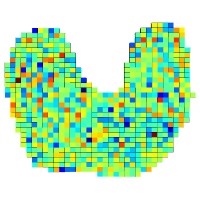

In [30]:
# add a colorbar to the prisms
model_vedo.add_scalarbar(
    title="Magnetização (A/m)", 
    pos=((0.9,0.05),(0.95,0.55)),
    title_yoffset=15,
    font_size=14,
    nlabels=10,
    horizontal=False,
    label_format=':6.2f'
)

In [34]:
pl = vedo.Plotter()

pl += model_vedo

pl += aux_vedo.custom_axes(model_area+[-500, 1000])

# set a model view
pl.show(
    axes=0, 
    zoom=1, 
    interactive=True,
    #viewup=(-0.3591183514135307, -0.23430478783991432, -0.9034020567130234), 
    elevation=-260, roll=1, azimuth=0
)

# save the chosen view
pl.show(axes=0, zoom=0.95, interactive=False)
pl.screenshot('model/3_model_view.png')
pl.interactive()
# pl.close()

In [35]:
pl.close()